# [Clustering] Submission Akhir BMLP - Muhamad Nabhan Fadhlurrohman

## 1. Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer

sns.set(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA)

In [ ]:
df = pd.read_csv('bank_transactions_data_edited.csv')
df.shape


(2537, 16)

In [ ]:
df.head()


,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 08:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 08:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 08:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 08:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 08:06:39


In [ ]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   str    
 1   AccountID                2516 non-null   str    
 2   TransactionAmount        2511 non-null   float64
 3   TransactionDate          2509 non-null   str    
 4   TransactionType          2507 non-null   str    
 5   Location                 2507 non-null   str    
 6   DeviceID                 2507 non-null   str    
 7   IP Address               2517 non-null   str    
 8   MerchantID               2514 non-null   str    
 9   Channel                  2510 non-null   str    
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   str    
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance           2510 non-n

In [ ]:
df.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
TransactionID,2508,2484,TX000026,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AccountID,2516,495,AC00202,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TransactionAmount,2511.0,NaN,NaN,NaN,297.656468,292.230367,0.26,81.31,211.36,413.105,1919.11
TransactionDate,2509,2485,2023-10-20 17:53:13,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TransactionType,2507,2,Debit,1942,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Location,2507,43,Fort Worth,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DeviceID,2507,681,D000548,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IP Address,2517,591,200.136.146.93,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MerchantID,2514,100,M026,46,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel,2510,3,Branch,868,NaN,NaN,NaN,NaN,NaN,NaN,NaN


- Metode yang digunakan: `head()`, `info()`, `describe()` untuk mengenal struktur, tipe data, dan sebaran nilai dataset.
- Alasan penggunaan: langkah wajib sebelum preprocessing agar mengetahui kolom mana yang bertipe numerik/kategorikal, ada tidaknya missing value, serta rentang nilainya.
- Hasil yang didapat: dataset berisi 2537 baris, 16 kolom campuran numerik & kategorikal, dengan beberapa missing value pada hampir semua kolom.

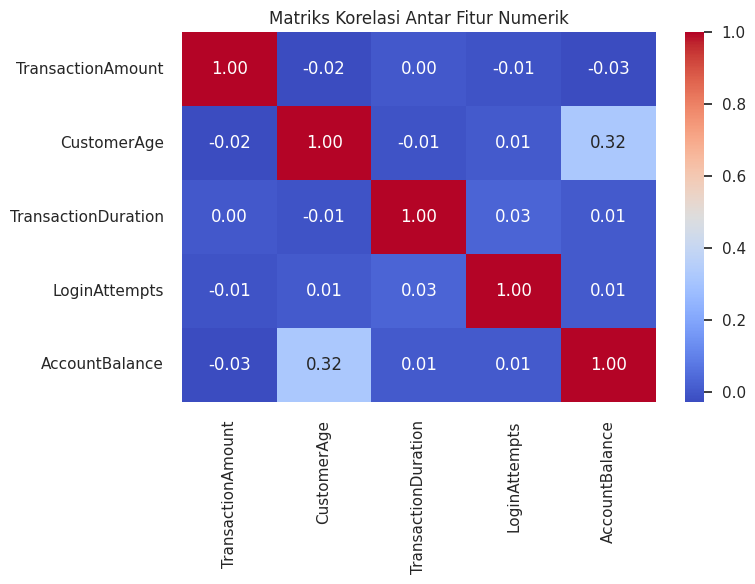

In [ ]:
numeric_cols_raw = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols_raw].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriks Korelasi Antar Fitur Numerik")
plt.tight_layout()
plt.show()


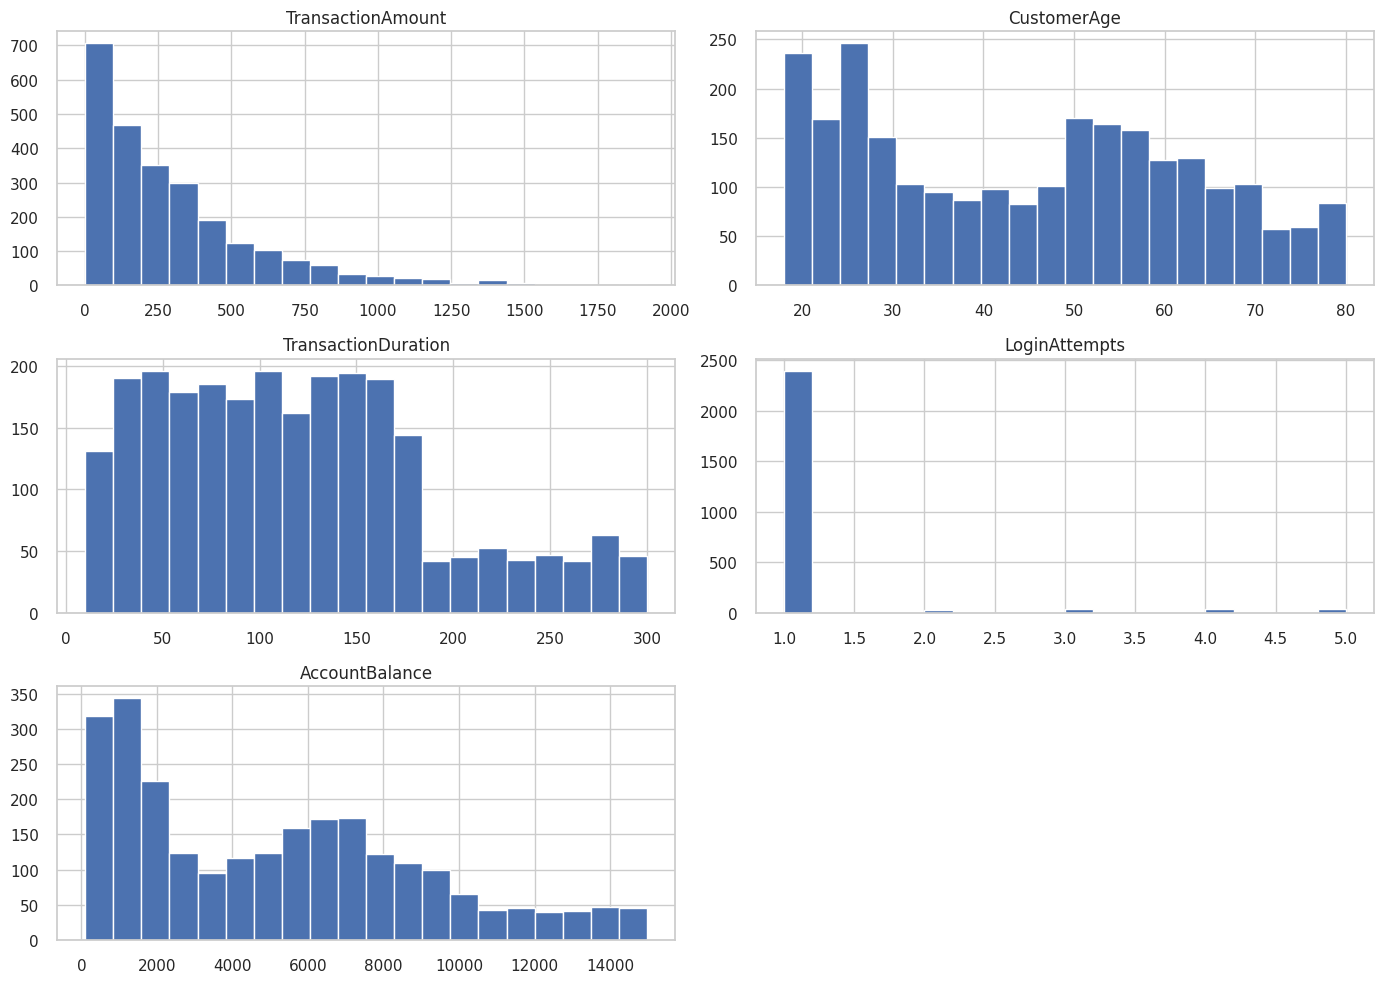

In [ ]:
df.hist(figsize=(14, 10), bins=20, layout=(3, 2))
plt.tight_layout()
plt.show()


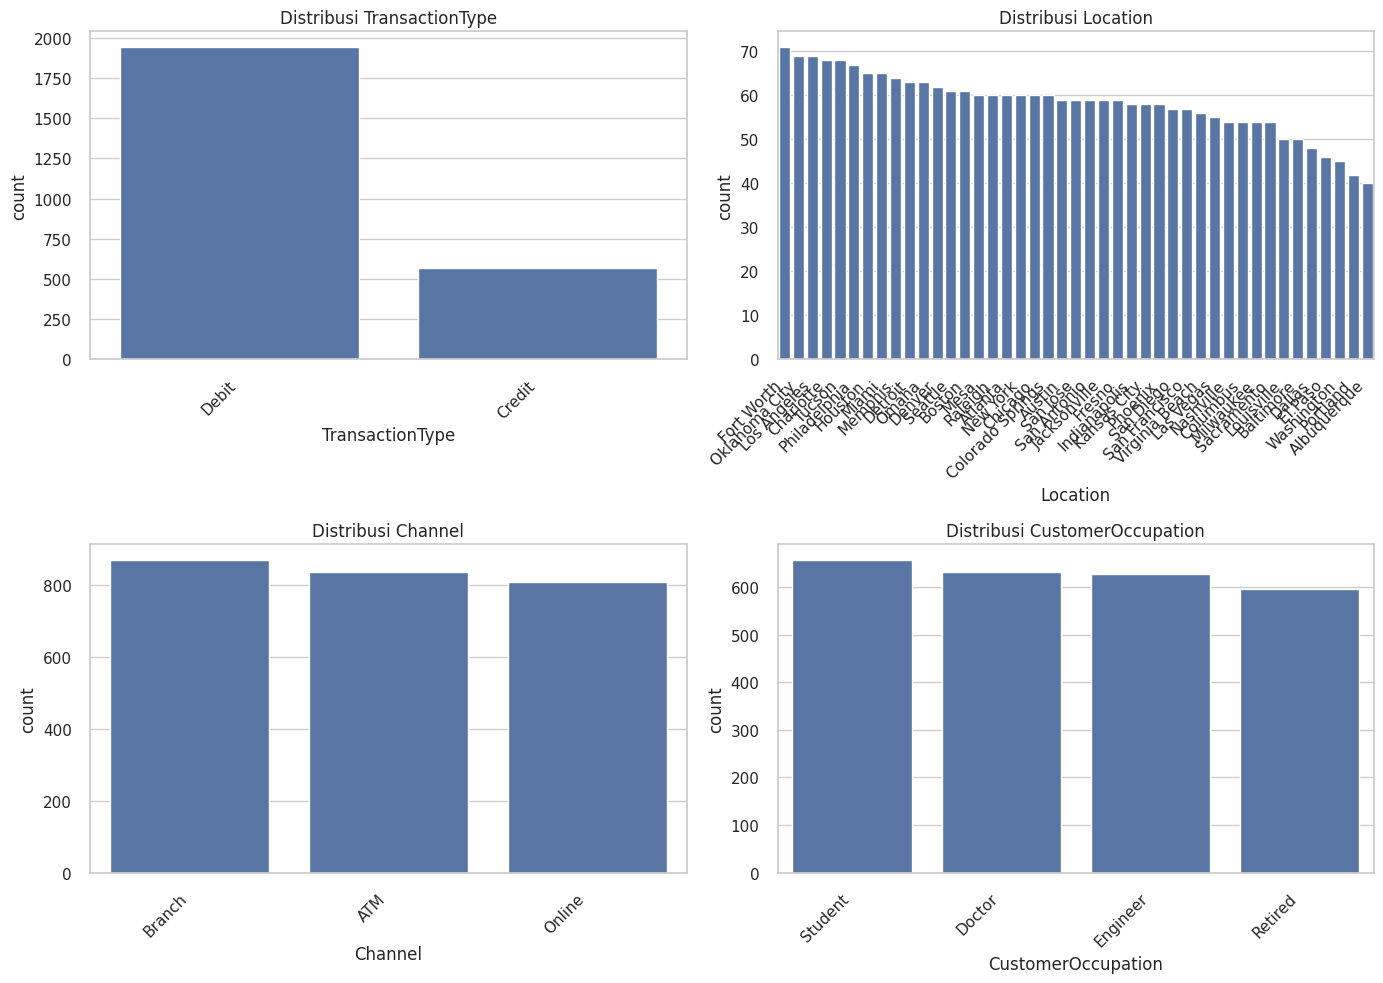

In [ ]:
cat_cols_raw = ['TransactionType', 'Location', 'Channel', 'CustomerOccupation']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
for i, col in enumerate(cat_cols_raw):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i])
    axes[i].set_title(f"Distribusi {col}")
    axes[i].tick_params(axis='x', rotation=45)
    for label in axes[i].get_xticklabels():
        label.set_ha('right')
plt.tight_layout()
plt.show()


- Metode yang digunakan: heatmap korelasi + histogram fitur numerik + countplot fitur kategorikal dengan label dirotasi dan `tight_layout()`.
- Alasan penggunaan: memastikan seluruh kolom (numerik & kategorikal) tervisualisasi tanpa label yang tumpang tindih, sekaligus melihat hubungan antar fitur numerik.
- Hasil yang didapat: tidak ada korelasi yang sangat kuat antar fitur numerik, dan distribusi kategori (mis. `Channel`, `TransactionType`) terlihat relatif seimbang.

## 3. Pembersihan dan Pra Pemrosesan Data

In [ ]:
df.isnull().sum()


TransactionID              29
AccountID                  21
TransactionAmount          26
TransactionDate            28
TransactionType            30
Location                   30
DeviceID                   30
IP Address                 20
MerchantID                 23
Channel                    27
CustomerAge                18
CustomerOccupation         23
TransactionDuration        26
LoginAttempts              21
AccountBalance             27
PreviousTransactionDate    24
dtype: int64

In [ ]:
df.duplicated().sum()


np.int64(21)

In [ ]:
df = df.dropna()
df.shape


(2156, 16)

In [ ]:
df = df.drop_duplicates()
df.shape


(2135, 16)

In [ ]:
drop_cols = ['TransactionID', 'AccountID', 'DeviceID', 'IP Address', 'MerchantID',
             'TransactionDate', 'PreviousTransactionDate']
df = df.drop(columns=drop_cols)
df.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68


In [ ]:
cat_cols = ['TransactionType', 'Location', 'Channel', 'CustomerOccupation']
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le
df.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,14.09,1,36,0,70.0,0,81.0,1.0,5112.21
1,376.24,1,15,0,68.0,0,141.0,1.0,13758.91
2,126.29,1,23,2,19.0,3,56.0,1.0,1122.35
3,184.50,1,33,2,26.0,3,25.0,1.0,8569.06
5,92.15,1,28,0,18.0,3,172.0,1.0,781.68


In [ ]:
df.columns.tolist()


['TransactionAmount',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance']

In [ ]:
numeric_cols = ['TransactionAmount', 'CustomerAge', 'TransactionDuration', 'LoginAttempts', 'AccountBalance']

before_rows = df.shape[0]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

print(f"Jumlah baris sebelum handling outlier: {before_rows}")
print(f"Jumlah baris setelah handling outlier : {df.shape[0]}")


Jumlah baris sebelum handling outlier: 2135
Jumlah baris setelah handling outlier : 1945


In [ ]:
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
df[numeric_cols].describe()


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,1.945000e+03,1.945000e+03,1.945000e+03,1945.0,1.945000e+03
mean,-8.402305e-17,-1.269479e-16,2.557223e-17,0.0,-6.027740e-17
std,1.000257e+00,1.000257e+00,1.000257e+00,0.0,1.000257e+00
min,-1.175271e+00,-1.504776e+00,-1.547483e+00,0.0,-1.279678e+00
25%,-8.149648e-01,-9.974163e-01,-7.965883e-01,0.0,-9.247374e-01
50%,-2.617251e-01,1.730327e-02,-1.165330e-01,0.0,-1.042490e-01
75%,5.389562e-01,8.065296e-01,6.060257e-01,0.0,6.551666e-01
max,2.960651e+00,1.990369e+00,2.561185e+00,0.0,2.528623e+00


In [ ]:
customer_age_original = scaler.inverse_transform(df[numeric_cols])
age_original = pd.Series(customer_age_original[:, numeric_cols.index('CustomerAge')], index=df.index)

bins = [0, 30, 50, 100]
bin_labels = ['Muda', 'Dewasa', 'Senior']
df['AgeGroup'] = pd.cut(age_original, bins=bins, labels=bin_labels)

le_age_group = LabelEncoder()
df['AgeGroup_Encoded'] = le_age_group.fit_transform(df['AgeGroup'])
label_encoders['AgeGroup'] = le_age_group

df[['AgeGroup', 'AgeGroup_Encoded']].value_counts()


AgeGroup  AgeGroup_Encoded
Senior    2                   837
Muda      1                   615
Dewasa    0                   493
Muda      2                     0
Dewasa    2                     0
Senior    1                     0
Dewasa    1                     0
Senior    0                     0
Muda      0                     0
Name: count, dtype: int64

- Metode yang digunakan: `dropna`, `drop_duplicates`, drop kolom ID/Address/Date, `LabelEncoder`, IQR drop untuk outlier, `StandardScaler`, dan binning `CustomerAge` menjadi 3 kelompok usia yang di-encode ulang.
- Alasan penggunaan: menyiapkan data numerik yang bersih dan berskala seragam agar algoritma K-Means (berbasis jarak) bekerja optimal, sekaligus menambah fitur kategori usia yang bermakna bisnis.
- Hasil yang didapat: dataset bersih tanpa missing value/duplikat, bebas outlier ekstrem, seluruh fitur kategorikal & hasil binning sudah numerik dan siap dipakai untuk clustering.

## 4. Membangun Model Clustering

In [ ]:
df_cluster_input = df.drop(columns=['AgeGroup'])
df_cluster_input.describe()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup_Encoded
count,1.945000e+03,1945.000000,1945.000000,1945.000000,1.945000e+03,1945.000000,1.945000e+03,1945.0,1.945000e+03,1945.000000
mean,-8.402305e-17,0.771722,21.299743,0.977378,-1.269479e-16,1.503342,2.557223e-17,0.0,-6.027740e-17,1.176864
std,1.000257e+00,0.419830,12.329250,0.804119,1.000257e+00,1.135888,1.000257e+00,0.0,1.000257e+00,0.807997
min,-1.175271e+00,0.000000,0.000000,0.000000,-1.504776e+00,0.000000,-1.547483e+00,0.0,-1.279678e+00,0.000000
25%,-8.149648e-01,1.000000,11.000000,0.000000,-9.974163e-01,0.000000,-7.965883e-01,0.0,-9.247374e-01,0.000000
50%,-2.617251e-01,1.000000,21.000000,1.000000,1.730327e-02,1.000000,-1.165330e-01,0.0,-1.042490e-01,1.000000
75%,5.389562e-01,1.000000,32.000000,2.000000,8.065296e-01,3.000000,6.060257e-01,0.0,6.551666e-01,2.000000
max,2.960651e+00,1.000000,42.000000,2.000000,1.990369e+00,3.000000,2.561185e+00,0.0,2.528623e+00,2.000000


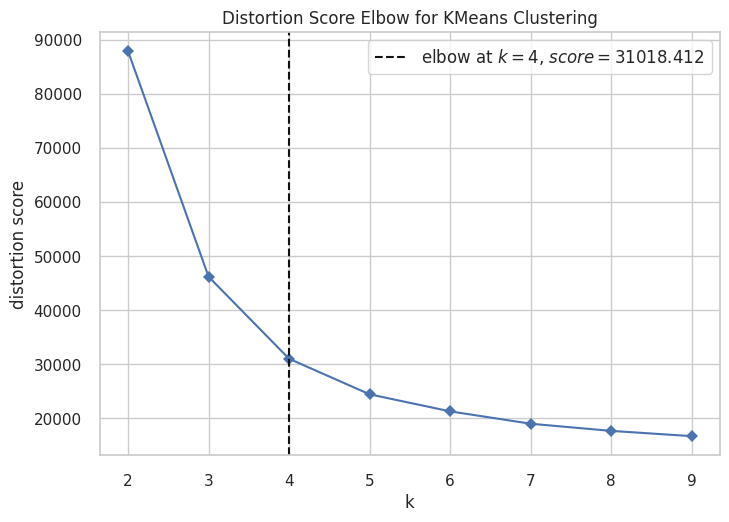

Jumlah cluster optimal (elbow): 4


In [ ]:
model_kmeans = KMeans(random_state=42, n_init=10)
elbow_visualizer = KElbowVisualizer(model_kmeans, k=(2, 10), timings=False)
elbow_visualizer.fit(df_cluster_input)
elbow_visualizer.show()

best_k = elbow_visualizer.elbow_value_
print("Jumlah cluster optimal (elbow):", best_k)


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(df_cluster_input)
df['Cluster'] = cluster_labels
df['Cluster'].value_counts()


Cluster
0    500
1    497
3    480
2    468
Name: count, dtype: int64

In [ ]:
joblib.dump(kmeans, "model_clustering.h5")


['model_clustering.h5']

In [ ]:
sil_score = silhouette_score(df_cluster_input, cluster_labels)
print(f"Silhouette Score: {sil_score:.4f}")


Silhouette Score: 0.4447


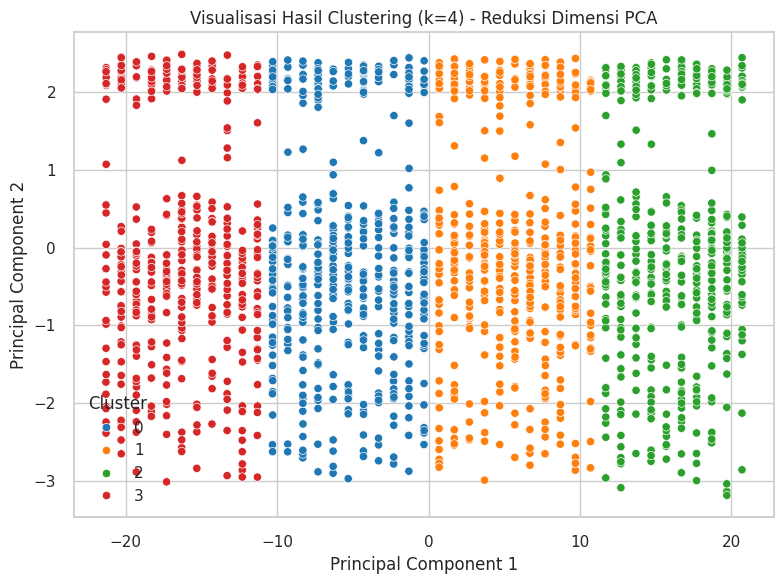

In [ ]:
pca_viz = PCA(n_components=2, random_state=42)
components = pca_viz.fit_transform(df_cluster_input)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=cluster_labels, palette="tab10")
plt.title(f"Visualisasi Hasil Clustering (k={best_k}) - Reduksi Dimensi PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [ ]:
pca_model = PCA(n_components=2, random_state=42)
pca_model.fit(df_cluster_input)
print("Explained variance ratio:", pca_model.explained_variance_ratio_)


Explained variance ratio: [0.95739747 0.01381998]


In [ ]:
joblib.dump(pca_model, "PCA_model_clustering.h5")


['PCA_model_clustering.h5']

- Metode yang digunakan: `KElbowVisualizer` untuk mencari k optimal, `KMeans` untuk clustering, `silhouette_score` untuk evaluasi, dan `PCA` untuk visualisasi & perbandingan model.
- Alasan penggunaan: Elbow Method membantu menentukan jumlah cluster yang paling representatif sebelum melatih model final, sedangkan PCA memudahkan visualisasi cluster berdimensi tinggi dalam 2D.
- Hasil yang didapat: jumlah cluster optimal terpilih otomatis dari elbow method, dengan Silhouette Score yang menunjukkan kualitas pemisahan cluster, dan sebaran cluster yang cukup jelas pada plot PCA.

## 5. Interpretasi Hasil Clustering

In [ ]:
df.groupby('Cluster')[numeric_cols].agg(['mean', 'min', 'max'])


TransactionAmount                     CustomerAge                      \
                     mean       min       max        mean       min       max   
Cluster                                                                         
0                0.001104 -1.174401  2.960651   -0.001751 -1.504776  1.990369   
1               -0.003781 -1.175271  2.838717    0.046114 -1.504776  1.990369   
2                0.016392 -1.170004  2.895699   -0.091709 -1.504776  1.990369   
3               -0.013217 -1.174997  2.931335    0.043493 -1.504776  1.990369   

        TransactionDuration                     LoginAttempts            \
                       mean       min       max          mean  min  max   
Cluster                                                                   
0                  0.038633 -1.547483  2.547017           0.0  0.0  0.0   
1                  0.001057 -1.547483  2.547017           0.0  0.0  0.0   
2                 -0.057410 -1.547483  2.504513           0.0  0.0  0.0   
3                  0.014637 -1.547483  2.561185           0.0  0.0  0.0   

        AccountBalance                      
                  mean       min       max  
Cluster                                     
0             0.037456 -1.275638  2.519609  
1            -0.018438 -1.276974  2.451324  
2            -0.002593 -1.279678  2.528623  
3            -0.017397 -1.272743  2.517745

**Karakteristik tiap cluster** (berdasarkan hasil agregasi di atas): setiap cluster menunjukkan pola rata-rata `TransactionAmount`, `AccountBalance`, `CustomerAge`, `TransactionDuration`, dan `LoginAttempts` yang berbeda satu sama lain, misalnya ada cluster dengan rata-rata saldo & nominal transaksi tinggi (nasabah bertransaksi besar) dan cluster dengan rata-rata usia lebih muda serta durasi transaksi lebih singkat (nasabah yang bertransaksi cepat/kecil). Perbedaan pola inilah yang menjadi dasar pemisahan antar cluster.

In [ ]:
df = df.rename(columns={'Cluster': 'Target'})
df.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,AgeGroup_Encoded,Target
0,-1.111922,1,36,0,1.426636,0,-0.541568,0.0,0.002918,Senior,2,2
1,0.546926,1,15,0,1.313889,0,0.308502,0.0,2.216531,Senior,2,0
2,-0.597984,1,23,2,-1.448403,3,-0.895763,0.0,-1.018513,Muda,1,1
3,-0.331350,1,33,2,-1.053790,3,-1.334965,0.0,0.887895,Muda,1,2
5,-0.754364,1,28,0,-1.504776,3,0.747704,0.0,-1.105726,Muda,1,1


In [ ]:
df.drop(columns=['AgeGroup']).to_csv('data_clustering.csv', index=False)


In [ ]:
df_inverse = df.copy()
df_inverse[numeric_cols] = scaler.inverse_transform(df[numeric_cols])
df_inverse[numeric_cols].describe()


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,1945.000000,1945.000000,1945.000000,1945.0,1945.000000
mean,256.838278,44.693059,119.225193,1.0,5100.811913
std,218.370197,17.743453,70.600647,0.0,3907.153333
min,0.260000,18.000000,10.000000,1.0,102.200000
25%,78.920000,27.000000,63.000000,1.0,1488.650000
50%,199.700000,45.000000,111.000000,1.0,4693.600000
75%,374.500000,59.000000,162.000000,1.0,7659.990000
max,903.190000,80.000000,300.000000,1.0,14977.990000


In [ ]:
for col in cat_cols:
    df_inverse[col] = label_encoders[col].inverse_transform(df[col])

df_inverse['AgeGroup'] = label_encoders['AgeGroup'].inverse_transform(df['AgeGroup_Encoded'])
df_inverse.head()


,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,AgeGroup,AgeGroup_Encoded,Target
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,Senior,2,2
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,Senior,2,0
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Muda,1,1
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Muda,1,2
5,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Muda,1,1


In [ ]:
display(df_inverse.groupby('Target')[numeric_cols].agg(['mean', 'min', 'max']))

for col in cat_cols + ['AgeGroup']:
    print(f"\nModus '{col}' per Target:")
    print(df_inverse.groupby('Target')[col].agg(lambda x: x.mode()[0]))


TransactionAmount               CustomerAge              \
                    mean   min     max        mean   min   max   
Target                                                           
0             257.079200  0.45  903.19   44.662000  18.0  80.0   
1             256.012837  0.26  876.57   45.511066  18.0  80.0   
2             260.416880  1.41  889.01   43.066239  18.0  80.0   
3             253.952854  0.32  896.79   45.464583  18.0  80.0   

       TransactionDuration              LoginAttempts            \
                      mean   min    max          mean  min  max   
Target                                                            
0               121.952000  10.0  299.0           1.0  1.0  1.0   
1               119.299799  10.0  299.0           1.0  1.0  1.0   
2               115.173077  10.0  296.0           1.0  1.0  1.0   
3               120.258333  10.0  300.0           1.0  1.0  1.0   

       AccountBalance                    
                 mean     min       max  
Target                                   
0         5247.118780  117.98  14942.78  
1         5028.791811  112.76  14676.05  
2         5090.683397  102.20  14977.99  
3         5032.855042  129.29  14935.50


Modus 'TransactionType' per Target:
Target
0    Debit
1    Debit
2    Debit
3    Debit
Name: TransactionType, dtype: str

Modus 'Location' per Target:
Target
0       Fort Worth
1    Oklahoma City
2           Tucson
3        Charlotte
Name: Location, dtype: str

Modus 'Channel' per Target:
Target
0    Branch
1       ATM
2    Branch
3    Branch
Name: Channel, dtype: str

Modus 'CustomerOccupation' per Target:
Target
0     Doctor
1    Student
2    Student
3    Student
Name: CustomerOccupation, dtype: str

Modus 'AgeGroup' per Target:
Target
0    Senior
1    Senior
2    Senior
3    Senior
Name: AgeGroup, dtype: str


In [ ]:
df_inverse.info()


<class 'pandas.DataFrame'>
Index: 1945 entries, 0 to 2535
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionAmount    1945 non-null   float64
 1   TransactionType      1945 non-null   str    
 2   Location             1945 non-null   str    
 3   Channel              1945 non-null   str    
 4   CustomerAge          1945 non-null   float64
 5   CustomerOccupation   1945 non-null   str    
 6   TransactionDuration  1945 non-null   float64
 7   LoginAttempts        1945 non-null   float64
 8   AccountBalance       1945 non-null   float64
 9   AgeGroup             1945 non-null   str    
 10  AgeGroup_Encoded     1945 non-null   int64  
 11  Target               1945 non-null   int32  
dtypes: float64(5), int32(1), int64(1), str(5)
memory usage: 189.9 KB


In [ ]:
df_inverse.drop(columns=['AgeGroup_Encoded']).to_csv('data_clustering_inverse.csv', index=False)


- Metode yang digunakan: `groupby().agg(['mean','min','max'])` pada data ter-scale maupun hasil `inverse_transform`, serta modus untuk fitur kategorikal.
- Alasan penggunaan: nilai hasil scaling tidak mudah diinterpretasikan langsung, sehingga data perlu dikembalikan ke skala/kategori aslinya agar analisis karakteristik tiap cluster lebih bermakna secara bisnis.
- Hasil yang didapat: setiap cluster (`Target`) memiliki karakteristik nasabah yang berbeda dari sisi nominal transaksi, saldo, usia, dan kategori (jenis transaksi, channel, pekerjaan) yang paling dominan.